In [2]:
import numpy as np
from lib.utils import *
from lib.local_utils import *
from lib.vqe import DVR_VQE
from lib.pot_gen import get_pot, get_pot_cr2
from lib.dvr2d import pauli_decompose

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

cmap = plt.get_cmap('tab10')
plt.rcParams["figure.figsize"] = (5,5)
plt.rcParams["font.size"] = 12
plt.rcParams["figure.dpi"] = 200

%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
ref_full = np.load(scratch_dir + 'refs/converged/refs.npz', allow_pickle=True)
ref_constrained = np.load(scratch_dir + 'refs/constrained/refs.npz', allow_pickle=True)
print(ref_full.files)
print(ref_constrained.files)

['arhcl', 'mgnh', 'cr2_1', 'cr2_3', 'cr2_5', 'cr2_7', 'cr2_9', 'cr2_11', 'cr2_13']
['arhcl_32', 'mgnh_32', 'arhcl_64', 'mgnh_64', 'cr2_1_8', 'cr2_1_16', 'cr2_3_8', 'cr2_3_16', 'cr2_5_8', 'cr2_5_16', 'cr2_7_8', 'cr2_7_16', 'cr2_9_8', 'cr2_9_16', 'cr2_11_8', 'cr2_11_16', 'cr2_13_8', 'cr2_13_16']


In [4]:
refs = ref_full['cr2_13']
print(refs)

[-5.48681073e+02 -4.97158591e+02 -4.49179344e+02 ...  9.65133419e+05
  9.83208805e+05  1.01296621e+06]


In [5]:
from lib.dvr2d import arhcl_params
from lib.dvr1d import cr2_params

mol_params = cr2_params
spin = 13
mol_params['name'] += f'_{spin}'

# 16 points
params16 = [5.2, 9]

dvr_options_8 = {
    'type': '1d',
    'box_lims': (params16[0], params16[1]),
    'dx': (params16[1] - params16[0]) / 8,
    'count': 8
}

dvr_options_16 = {
    'type': '1d',
    'box_lims': (params16[0], params16[1]),
    'dx': (params16[1] - params16[0]) / 16,
    'count': 16
}

# 32 points
dvr_options_32 = {
    'type': '1d',
    'box_lims': (params16[0], params16[1]),
    'dx': (params16[1] - params16[0]) / 32,
    'count': 32
}

# 64 points
dvr_options_64 = {
    'type': '1d',
    'box_lims': (params16[0], params16[1]),
    'dx': (params16[1] - params16[0]) / 32,
    'count': 64
}

vqe_options = {
    # 'optimizers': ['COBYLA.8000', 'L_BFGS_B.8000', 'SLSQP.1000'],
    'optimizers': ['COBYLA.500'],
    'repeats': 3, 
    'seed': None
}

pot, lims = get_pot_cr2(spin)
dvr_vqe = DVR_VQE(mol_params, pot, log_dir=scratch_dir + 'single_params_test/')

In [6]:
%autoreload
h_dvr_8s = [dvr_vqe.get_h_dvr(dvr_options_8, offdiagonals=None) * hartree]
for i in range(10):
    h_dvr_8 = dvr_vqe.get_h_dvr(dvr_options_8, offdiagonals=i) * hartree
    h_dvr_8s.append(h_dvr_8)
h_dvr_8s = np.array(h_dvr_8s)

h_dvr_16s = [dvr_vqe.get_h_dvr(dvr_options_16, offdiagonals=None) * hartree]
for i in range(10):
    h_dvr_16 = dvr_vqe.get_h_dvr(dvr_options_16, offdiagonals=i) * hartree
    h_dvr_16s.append(h_dvr_16)
h_dvr_16s = np.array(h_dvr_16s)

h_dvr_32s = [dvr_vqe.get_h_dvr(dvr_options_32, offdiagonals=None) * hartree]
for i in range(10):
    h_dvr_32 = dvr_vqe.get_h_dvr(dvr_options_32, offdiagonals=i) * hartree
    h_dvr_32s.append(h_dvr_32)
h_dvr_32s = np.array(h_dvr_32s)

h_dvr_64s = [dvr_vqe.get_h_dvr(dvr_options_64, offdiagonals=None) * hartree]
for i in range(10):
    h_dvr_64 = dvr_vqe.get_h_dvr(dvr_options_64, offdiagonals=i) * hartree
    h_dvr_64s.append(h_dvr_64)
h_dvr_64s = np.array(h_dvr_64s)


In [7]:
print('8 points DVR')
for i in range(6):
    print(i-1, np.linalg.eigvalsh(h_dvr_8s[i]))
print('------------------------------')
print('16 points DVR')
for i in range(6):
    print(i-1, np.linalg.eigvalsh(h_dvr_16s[i]))
print('------------------------------')
print('32 points DVR')
for i in range(6):
    print(i-1, np.linalg.eigvalsh(h_dvr_32s[i]))
print('------------------------------')
print('64 points DVR')
for i in range(6):
    print(i-1, np.linalg.eigvalsh(h_dvr_64s[i]))

8 points DVR
-1 [-545.52977927 -503.93322006 -452.11256075 -362.46687173 -284.73793036
 -222.49966042 -164.17880038 -127.73361558]
0 [-532.89434304 -510.35323201 -453.24294051 -361.86595069 -283.61525943
 -221.07873463 -171.38968573 -128.75229251]
1 [-546.38648132 -502.25237765 -452.51542302 -362.48962746 -284.71006568
 -222.04689072 -164.93693057 -127.85464213]
2 [-545.53174032 -504.01430304 -451.93793762 -362.46385561 -284.72741743
 -222.45616266 -164.27978217 -127.78123969]
3 [-545.53287963 -503.9288164  -452.11439926 -362.44005004 -284.73192831
 -222.4916482  -164.19055235 -127.76216436]
4 [-545.5307132  -503.93207651 -452.11076863 -362.46924209 -284.72923453
 -222.49410921 -164.17303358 -127.7532608 ]
------------------------------
16 points DVR
-1 [-548.67554318 -497.15325215 -449.26088962 -404.67410888 -362.99006359
 -325.72205626 -294.32712389 -263.10020988 -230.11943577 -196.2987776
 -157.68112791 -131.03499787 -105.54237729  -41.17526055   58.14172189
  249.96266379]
0 [-446.

In [8]:
print('8 points DVR')
for i in range(6):
    print(i-1, len(pauli_decompose(h_dvr_8s[i]).coeffs))
print('------------------------------')
print('16 points DVR')
for i in range(6):
    print(i-1, len(pauli_decompose(h_dvr_16s[i]).coeffs))
print('------------------------------')
print('32 points DVR')
for i in range(6):
    print(i-1, len(pauli_decompose(h_dvr_32s[i]).coeffs))
print('------------------------------')
print('64 points DVR')
for i in range(6):
    print(i-1, len(pauli_decompose(h_dvr_64s[i]).coeffs))

8 points DVR


-1 35
0 8
1 20
2 28
3 31
4 35
------------------------------
16 points DVR
-1 132
0 16
1 48
2 72
3 88
4 104
------------------------------
32 points DVR
-1 508
0 32
1 112
2 176
3 220
4 268
------------------------------
64 points DVR
-1 508
0 32
1 112
2 176
3 220
4 268


In [9]:
coeffs_8 = np.array(list(map(lambda h_dvr: len(pauli_decompose(h_dvr).coeffs), np.roll(h_dvr_8s, -1, axis=0))))
coeffs_16 = np.array(list(map(lambda h_dvr: len(pauli_decompose(h_dvr).coeffs), np.roll(h_dvr_16s, -1, axis=0))))
coeffs_32 = np.array(list(map(lambda h_dvr: len(pauli_decompose(h_dvr).coeffs), np.roll(h_dvr_32s, -1, axis=0))))
coeffs_64 = np.array(list(map(lambda h_dvr: len(pauli_decompose(h_dvr).coeffs), np.roll(h_dvr_64s, -1, axis=0))))


In [10]:
offs_8 = np.array(list(map(np.linalg.eigvalsh, np.roll(h_dvr_8s, -1, axis=0))))
offs_16 = np.array(list(map(np.linalg.eigvalsh, np.roll(h_dvr_16s, -1, axis=0))))
offs_32 = np.array(list(map(np.linalg.eigvalsh, np.roll(h_dvr_32s, -1, axis=0))))
offs_64 = np.array(list(map(np.linalg.eigvalsh, np.roll(h_dvr_64s, -1, axis=0))))

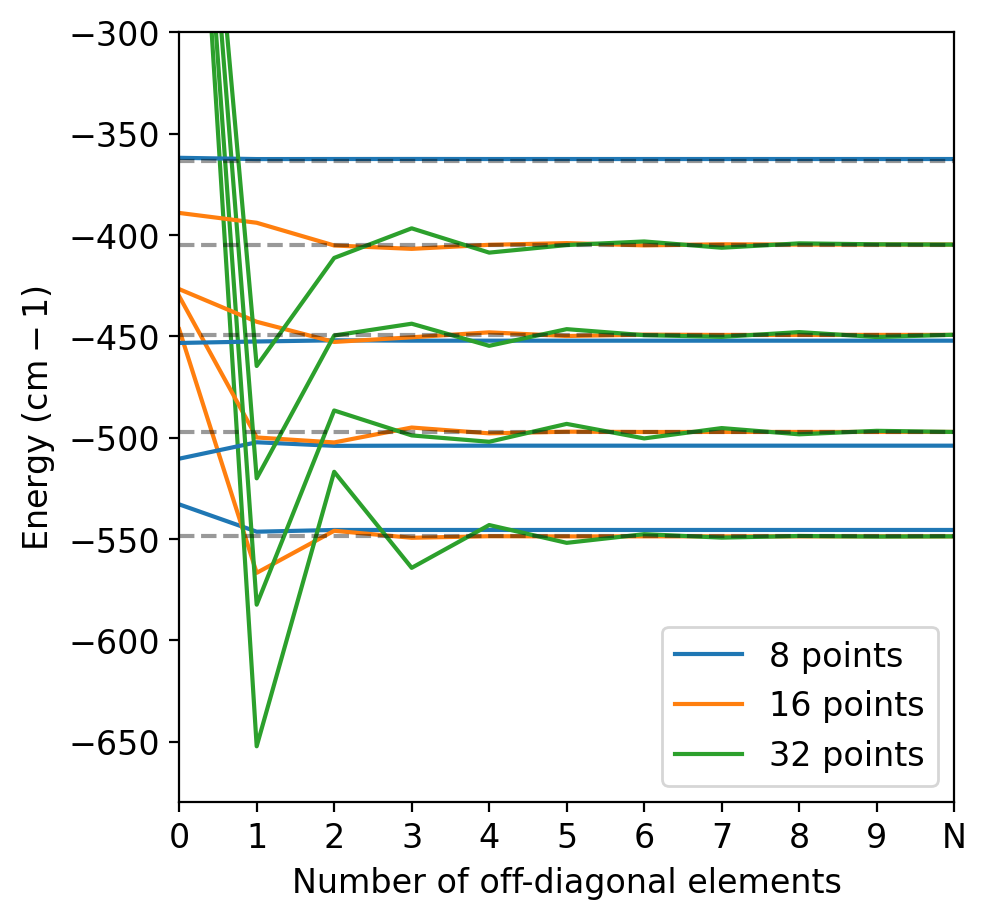

In [11]:
cmap = plt.get_cmap('tab10')

plt.plot(offs_8[:, 0], color=cmap(0), label='8 points')
plt.plot(offs_16[:, 0], color=cmap(1), label='16 points')
plt.plot(offs_32[:, 0], color=cmap(2), label='32 points')
for i in range(1, 4):
    plt.plot(offs_8[:, i], color=cmap(0))
    plt.plot(offs_16[:, i], color=cmap(1))
    plt.plot(offs_32[:, i], color=cmap(2))
for i in range(5):
    plt.axhline(refs[i], ls='--', color='black', alpha=0.4)
plt.xticks(range(11), [0, 1, 2, 3, 4, 5, 6, 7, 8, 9,'N'])
plt.xlabel('Number of off-diagonal elements')
plt.ylabel('Energy (cm${}-1$)')
plt.xlim(0, 10)
plt.ylim(-680, -300)
plt.legend()
plt.show()

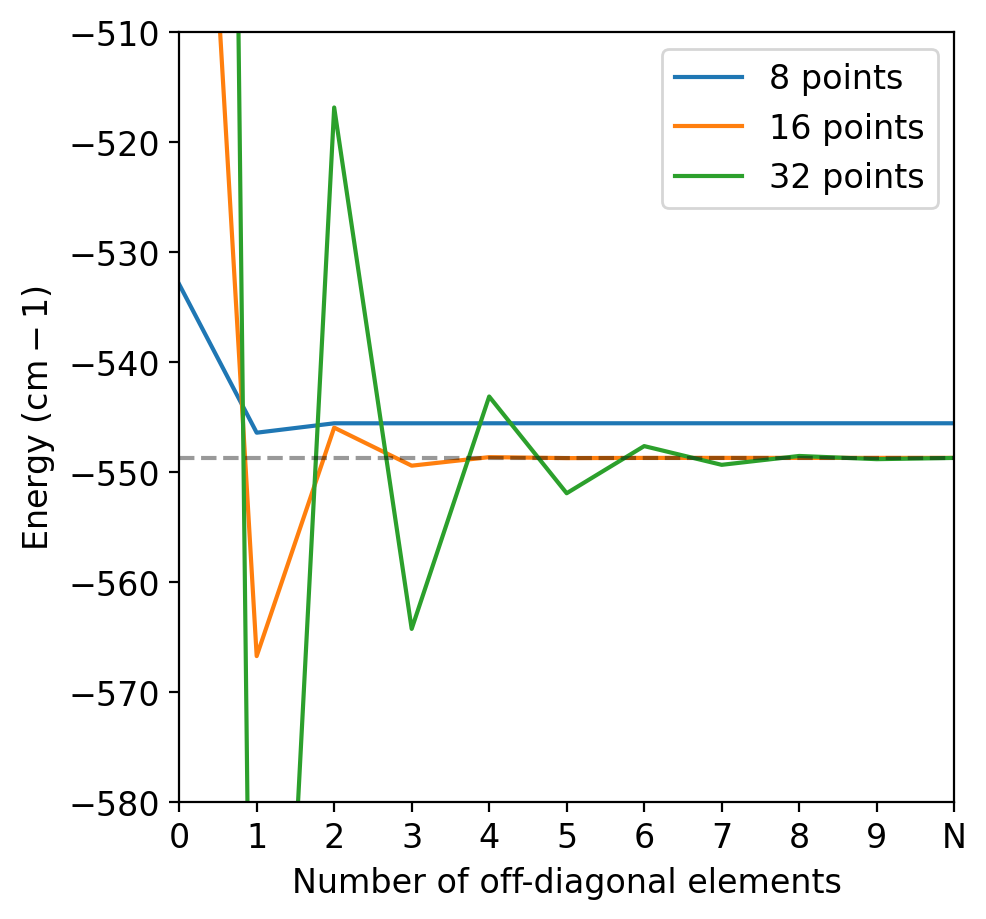

In [12]:
cmap = plt.get_cmap('tab10')

plt.plot(offs_8[:, 0], color=cmap(0), label='8 points')
plt.plot(offs_16[:, 0], color=cmap(1), label='16 points')
plt.plot(offs_32[:, 0], color=cmap(2), label='32 points')
for i in range(5):
    plt.axhline(refs[i], ls='--', color='black', alpha=0.4)
plt.xticks(range(11), [0, 1, 2, 3, 4, 5, 6, 7, 8, 9,'N'])
plt.xlabel('Number of off-diagonal elements')
plt.ylabel('Energy (cm${}-1$)')
plt.xlim(0, 10)
plt.ylim(-580, -510)
plt.legend()
plt.show()

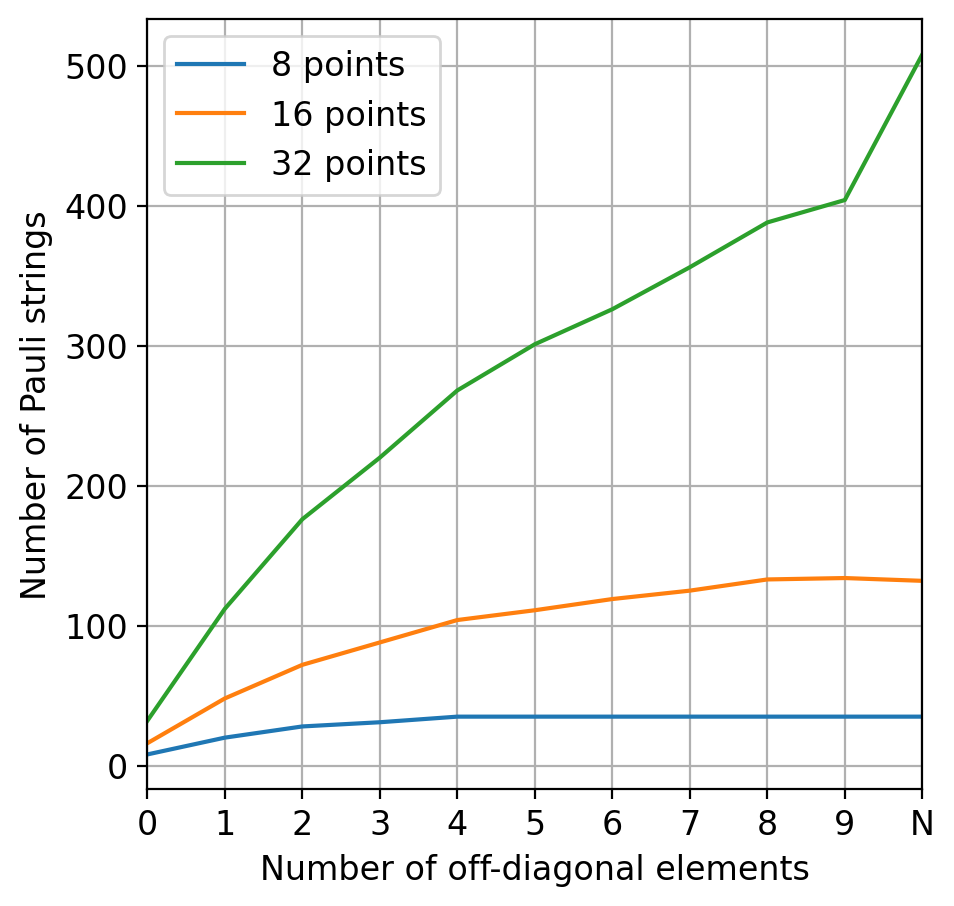

In [13]:
cmap = plt.get_cmap('tab10')

plt.plot(coeffs_8, color=cmap(0), label='8 points')
plt.plot(coeffs_16, color=cmap(1), label='16 points')
plt.plot(coeffs_32, color=cmap(2), label='32 points')

# plt.axhline(4**8, color=cmap(0), label='8 points')
# plt.plot(4**16, color=cmap(1), label='16 points')
# plt.plot(4**32, color=cmap(2), label='32 points')

plt.xticks(range(11), [0, 1, 2, 3, 4, 5, 6, 7, 8, 9,'N'])
plt.xlabel('Number of off-diagonal elements')
plt.ylabel('Number of Pauli strings')
plt.xlim(0, 10)
# plt.ylim(-680, -300)
plt.legend()
plt.grid()
plt.show()

In [25]:
h_dvr_32 = dvr_vqe.get_h_dvr(dvr_options_32) * hartree
print(h_dvr_32)

[[ 7.96402566e+02 -3.21907217e+02  8.04472189e+01 ... -3.59296804e-01
   3.34598053e-01 -3.12278559e-01]
 [-3.21907217e+02  5.35789926e+02 -3.21908984e+02 ...  3.87525989e-01
  -3.60080707e-01  3.35362357e-01]
 [ 8.04472189e+01 -3.21908984e+02  3.42065890e+02 ... -4.18894615e-01
   3.88290293e-01 -3.60826060e-01]
 ...
 [-3.59296804e-01  3.87525989e-01 -4.18894615e-01 ...  3.05228619e+02
  -3.21932964e+02  8.04722675e+01]
 [ 3.34598053e-01 -3.60080707e-01  3.88290293e-01 ... -3.21932964e+02
   3.16755138e+02 -3.21933361e+02]
 [-3.12278559e-01  3.35362357e-01 -3.60826060e-01 ...  8.04722675e+01
  -3.21933361e+02  3.27689340e+02]]


In [147]:
thresholds = np.linspace(0, 20, 21)
off_diagonals = range(2, 21)

coeffs = np.zeros((len(thresholds), len(off_diagonals)))
Egs = np.zeros_like(coeffs)

for i in range(len(thresholds)):
    for j in range(len(off_diagonals)):
        h_dvr_32 = dvr_vqe.get_h_dvr(dvr_options_32, offdiagonals=off_diagonals[j]) * hartree
        # print(h_dvr_32)
        h_dvr_32[np.abs(h_dvr_32) < thresholds[i]] = 0
        # print(h_dvr_32)

        eigvals = np.linalg.eigvalsh(h_dvr_32)
        Egs[i, j] = eigvals[0] - refs[0]
        coeffs[i, j] = len(pauli_decompose(h_dvr_32).coeffs)

In [148]:
print(thresholds)

[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20.]


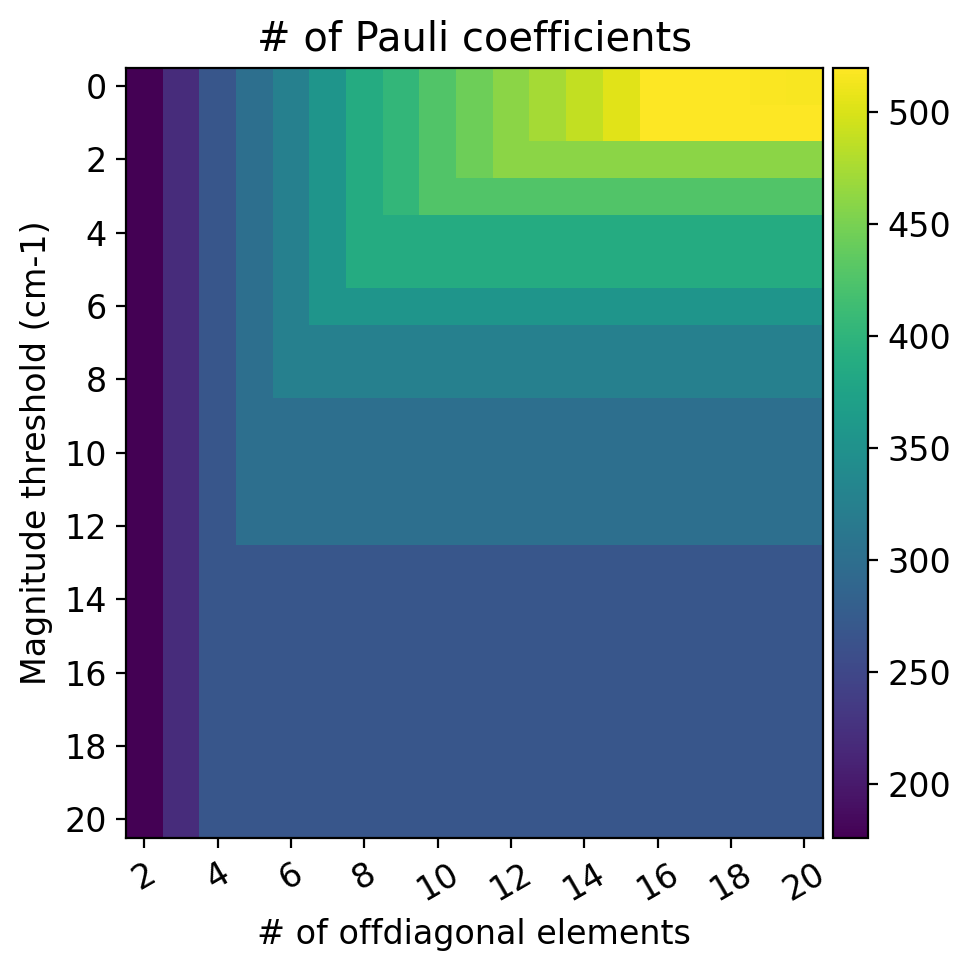

In [149]:
fig, ax = plt.subplots()

divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.05)

s = ax.imshow(coeffs, interpolation='nearest')
ax.set_xlabel('# of offdiagonal elements')
ax.set_ylabel('Magnitude threshold (cm-1)')
ax.set_title('# of Pauli coefficients')
ax.set_yticks(range(0, 21, 2))
ax.set_xticks(range(0, 19, 2), np.arange(0, 19, 2) + 2)
plt.setp(ax.get_xticklabels(), rotation=30,)

fig.colorbar(s, ax=ax, cax=cax)

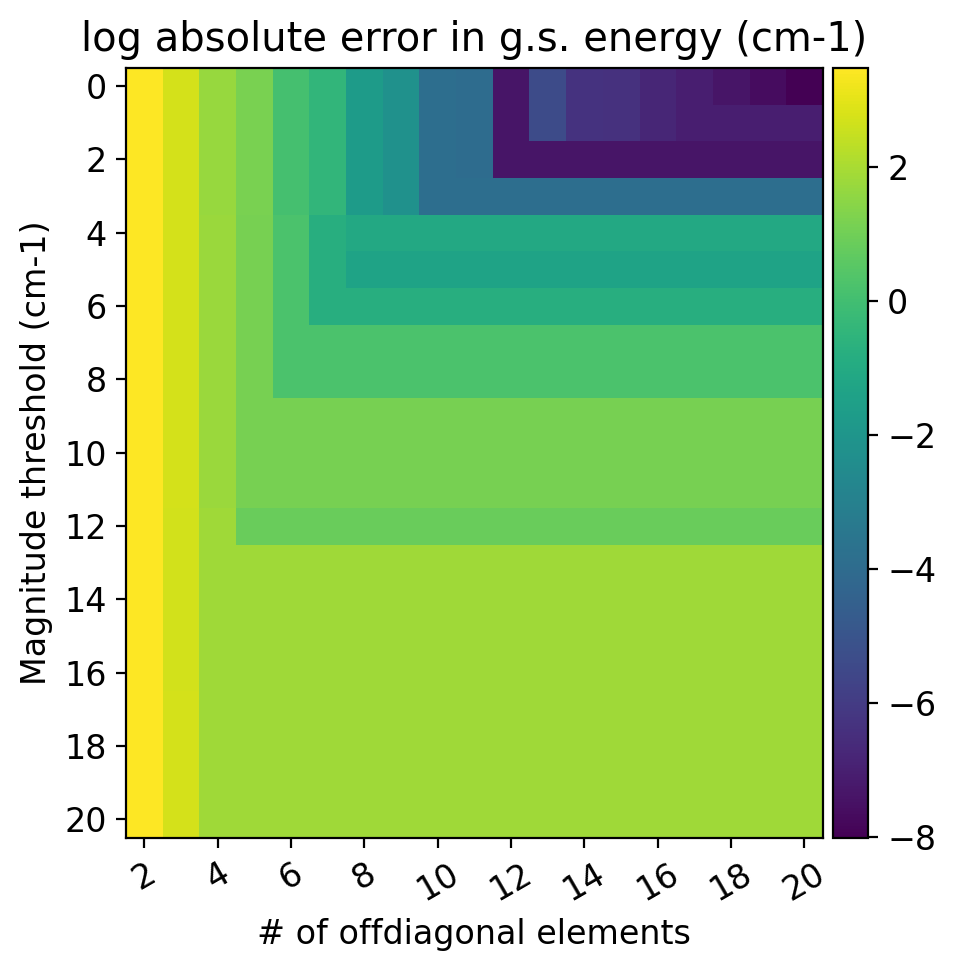

In [150]:
fig, ax = plt.subplots()

divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.05)

s = ax.imshow(np.log(np.abs(Egs)), interpolation='nearest')
ax.set_xlabel('# of offdiagonal elements')
ax.set_ylabel('Magnitude threshold (cm-1)')
ax.set_title('log absolute error in g.s. energy (cm-1)')
ax.set_yticks(range(0, 21, 2))
ax.set_xticks(range(0, 19, 2), np.arange(0, 19, 2) + 2)
plt.setp(ax.get_xticklabels(), rotation=30,)

fig.colorbar(s, ax=ax, cax=cax)

In [141]:
thresholds = np.linspace(0, 20, 21)
off_diagonals = range(2, 21)

coeffs = np.zeros((len(thresholds), len(off_diagonals)))
Egs = np.zeros_like(coeffs)

for i in range(len(thresholds)):
    for j in range(len(off_diagonals)):
        h_dvr_64 = dvr_vqe.get_h_dvr(dvr_options_64, offdiagonals=off_diagonals[j]) * hartree
        # print(h_dvr_64)
        h_dvr_64[np.abs(h_dvr_64) < thresholds[i]] = 0
        # print(h_dvr_64)

        eigvals = np.linalg.eigvalsh(h_dvr_64)
        Egs[i, j] = eigvals[0] - refs[0]
        coeffs[i, j] = len(pauli_decompose(h_dvr_64).coeffs)

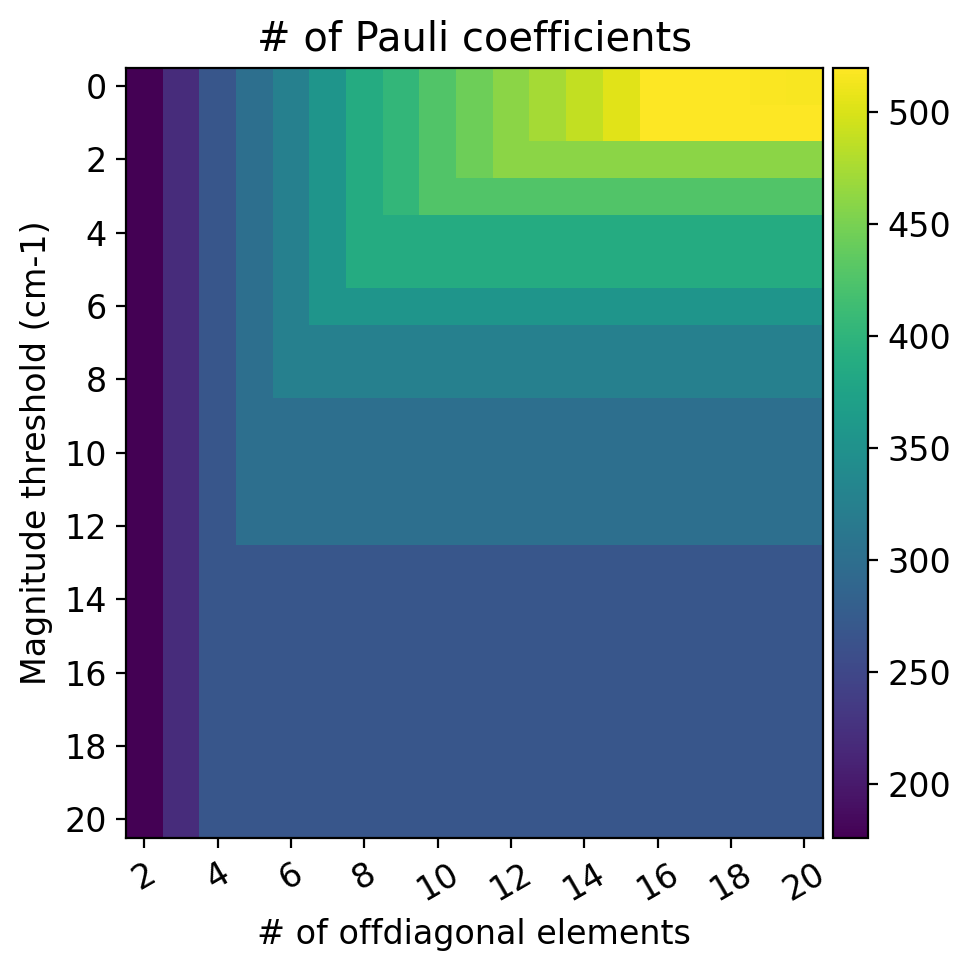

In [145]:
fig, ax = plt.subplots()

divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.05)

s = ax.imshow(coeffs, interpolation='nearest')
ax.set_xlabel('# of offdiagonal elements')
ax.set_ylabel('Magnitude threshold (cm-1)')
ax.set_title('# of Pauli coefficients')
ax.set_yticks(range(0, 21, 2))
ax.set_xticks(range(0, 19, 2), np.arange(0, 19, 2) + 2)
plt.setp(ax.get_xticklabels(), rotation=30,)

fig.colorbar(s, ax=ax, cax=cax)

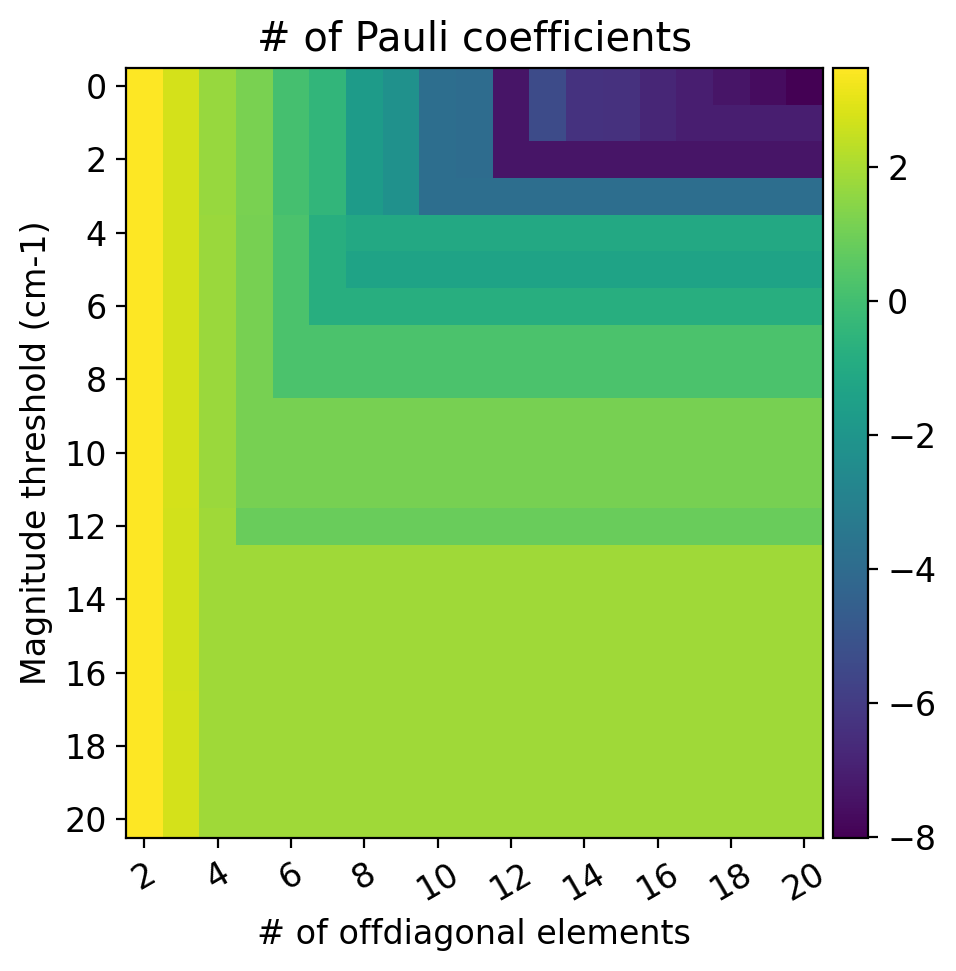

In [146]:
fig, ax = plt.subplots()

divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.05)

s = ax.imshow(np.log(np.abs(Egs)), interpolation='nearest')
ax.set_xlabel('# of offdiagonal elements')
ax.set_ylabel('Magnitude threshold (cm-1)')
ax.set_title('# of Pauli coefficients')
ax.set_yticks(range(0, 21, 2))
ax.set_xticks(range(0, 19, 2), np.arange(0, 19, 2) + 2)
plt.setp(ax.get_xticklabels(), rotation=30,)

fig.colorbar(s, ax=ax, cax=cax)